# R4 · Frozen RoBERTa-base

Mean contextual token vectors per article → mean articles per window → concat with market and availability → MLP `(64, 32)`. No query, cross-attention, or learned gate.

Reuse the R1–R3 folds, text spans, seeds, classifier, and training budget. **Final test stays locked.** Current inputs use `date_delay_sensitivity` / `audit_only`; they do not establish timestamp-verified forecasting.


In [1]:
from pathlib import Path
import copy
import os
import tempfile
import hashlib
import json
import platform
import time
from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from sklearn.utils import check_random_state
from IPython import get_ipython

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
import torch
import transformers
from transformers import AutoTokenizer, AutoModel
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "deira-work/SPLIT_PROTOCOL.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or a directory beneath it.")
BASE = ROOT / "deira-work/preprocessing/outputs/date_delay_sensitivity__audit_only"
MODEL_ID = "R4"
ENCODER_ID = "FacebookAI/roberta-base"
ENCODER_REVISION = "e2da8e2f811d1448a5b465c236feacd80ffbac7b"
ENCODER_DIM = 768
EXPECTED_WEIGHTS_SHA256 = "5bde1d28afb363d0103324efeb5afc8b2b397fe5e04beabb9b1ef355255ade81"
MAX_TOKENS = 512
ENCODER_BATCH_SIZE = 8
ENCODER_THREADS = 2
CACHE_ROOT = Path(tempfile.gettempdir()) / "deira-r4-roberta-cache"
HF_CACHE = CACHE_ROOT / "huggingface"
TEXT_FEATURES = [f"roberta_{i:03d}" for i in range(ENCODER_DIM)]
AVAIL_FEATURES = ["log1p_n_berita", "has_news"]
SEEDS = [42, 123, 2026]
MAX_EPOCHS = 200
PATIENCE = 25
MLP_CONFIG = dict(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                  alpha=1e-3, batch_size=32, learning_rate_init=1e-3,
                  max_iter=1, shuffle=True, early_stopping=False)
RUN_FINAL_TEST = False  # Enable only after the experiment configurations are frozen.
BOOTSTRAP_REPEATS = 1000
BLOCK_LENGTH = 10       # Evaluated fixing observations; circular moving blocks.
BOOTSTRAP_SEED = 20261110
LABELS = ["DOWN", "UP"]
METRICS = ["mcc", "macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "log_loss", "ece_10"]
COLORS = ["#2563eb", "#ea580c", "#059669"]
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"{MODEL_ID} | seeds: {SEEDS} | final test enabled: {RUN_FINAL_TEST}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"PyTorch {torch.__version__} | Transformers {transformers.__version__}")


R4 | seeds: [42, 123, 2026] | final test enabled: False
Python 3.12.3 | pandas 3.0.5 | NumPy 2.5.3 | Matplotlib 3.11.2
scikit-learn 1.9.1
PyTorch 2.9.0+cpu | Transformers 4.57.6


## Shared data

Load saved manifests and current source hashes. Same headline/180-word lead spans as R1–R3, derived from `data/processed/news_clean.csv`; the requested `data/preprocessed` file was absent. All learned scalers use training rows only.


In [2]:
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
pipeline = json.loads((BASE / "pipeline_manifest.json").read_text())
for name, expected in pipeline["input_sha256"].items():
    assert sha256(ROOT / name) == expected, f"Source snapshot changed: {name}"
assert pipeline["config"]["alignment_mode"] == "date_delay_sensitivity"
assert pipeline["config"]["geopolitical_policy"] == "audit_only"

contract = json.loads((BASE / "feature_contract.json").read_text())
MARKET_FEATURES = contract["market_features"]
FEATURES = MARKET_FEATURES.copy()
assert not set(FEATURES) & set(contract["target_and_diagnostic_columns_never_predictors"])
assert not set(FEATURES) & {"n_berita", "has_news", "y", "target_date", "next_jisdor"}
assert len(FEATURES) == len(set(FEATURES))
folds = pd.read_csv(BASE / "fold_manifest.csv", parse_dates=["Date", "target_date"])
final = pd.read_csv(BASE / "final_fit_manifest.csv", parse_dates=["Date", "target_date"])
daily = pd.read_csv(BASE / "daily_market.csv", parse_dates=["Date", "target_date"])
partitions = pd.read_csv(BASE / "calendar_partitions.csv", parse_dates=["Date", "target_date"])
assert not daily.Date.duplicated().any()
assert not folds.duplicated(["fold", "role", "Date"]).any()
assert not final.Date.duplicated().any()

def take_rows(rows):
    fields = ["Date", "target_date", "y", "eligible_binary", "n_berita", "has_news",
              "target_weekday", "realized_target_gap_days", *MARKET_FEATURES]
    joined = rows.merge(daily[fields], on="Date", how="left", validate="one_to_one", suffixes=("", "_daily"))
    assert len(joined) == len(rows) and joined.eligible_binary.all()
    assert joined.y.notna().all() and joined.y.isin([0, 1]).all()
    assert joined.target_date.eq(joined.target_date_daily).all()
    assert joined.y.eq(joined.y_daily).all()
    assert joined.n_berita.eq(joined.n_berita_daily).all()
    if "has_news_daily" in joined:
        assert joined.has_news.eq(joined.has_news_daily).all()
    assert np.isfinite(joined[MARKET_FEATURES].to_numpy(dtype=float)).all()
    return joined.drop(columns=[c for c in joined if c.endswith("_daily")]).sort_values("Date").reset_index(drop=True)

split_summary = []
seen_validation_dates = set()
for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    assert train.target_date.max() < val.Date.min()
    assert not set(train.Date) & set(val.Date)
    assert not seen_validation_dates & set(val.Date)
    seen_validation_dates.update(val.Date)
    for role, frame in [("train", train), ("validation", val)]:
        split_summary.append({"run": f"fold_{fold_id}", "role": role, "n": len(frame),
                              "first": frame.Date.min().date(), "last": frame.Date.max().date(),
                              "down": int(frame.y.eq(0).sum()), "up": int(frame.y.eq(1).sum()),
                              "news_days": int(frame.has_news.sum())})
final_train = take_rows(final.loc[final.role.eq("train")])
test_dates = final.loc[final.role.eq("test"), "Date"]
assert final_train.target_date.max() < test_dates.min()
assert not set(final_train.Date) & set(test_dates)
display(pd.DataFrame(split_summary))
print(f"Locked test: {test_dates.min().date()} to {test_dates.max().date()} | {len(test_dates)} eligible decisions")
print("Predictors:", ", ".join(FEATURES))
take_market_rows = take_rows


,run,role,n,first,last,down,up,news_days
0,fold_1,train,453,2021-09-29,2023-08-15,193,260,65
1,fold_1,validation,158,2023-08-21,2024-04-19,64,94,21
2,fold_2,train,612,2021-09-29,2024-04-19,257,355,86
3,fold_2,validation,159,2024-04-23,2024-12-12,78,81,32
4,fold_3,train,772,2021-09-29,2024-12-12,335,437,118
5,fold_3,validation,158,2024-12-16,2025-08-26,79,79,22


Locked test: 2025-08-29 to 2026-08-31 | 235 eligible decisions
Predictors: log_return_t, return_lag1, return_lag2, return_lag3, return_lag5, volatility_5, volatility_20, ma_ratio_5, ma_ratio_20, momentum_5, momentum_10, rsi_14, input_gap_days, decision_weekday


## Frozen article embeddings

[RoBERTa-base model card](https://huggingface.co/FacebookAI/roberta-base/blob/e2da8e2f811d1448a5b465c236feacd80ffbac7b/README.md). Revision `e2da8e2f811d1448a5b465c236feacd80ffbac7b`; verify the published weights SHA-256. Use the case-preserving byte-level BPE tokenizer as supplied, with `add_prefix_space=False` and no extra stemming or stopword removal.

Mean the last hidden state over content tokens, excluding special and padding tokens; then uniformly mean articles per window. Freeze the encoder in evaluation mode. Cap at 512 tokens and report truncation/unknown-token counts. Empty windows are exact zeros. Native width 768; adapter parameters: 0. Pretraining and historical checkpoint availability are not treated as identical to FinBERT.


In [3]:
article_path, window_path = BASE / "aligned_articles.jsonl", BASE / "news_windows.jsonl"
articles = pd.read_json(article_path, lines=True)
windows = pd.read_json(window_path, lines=True)
windows["Date"] = pd.to_datetime(windows.Date)
articles["anchor_date"] = pd.to_datetime(articles.anchor_date)
assert articles.article_id.is_unique and windows.Date.is_unique
assert np.array_equal(windows.Date.to_numpy(), daily.Date.to_numpy())
assert np.array_equal(windows.n_berita.to_numpy(), daily.n_berita.to_numpy())
assert not articles.known_temporal_contamination.any()
assert articles.text_transformer.eq(articles.text_shared).all()
assert all(len(w.article_ids) == w.n_berita for w in windows.itertuples())
article_index = articles.set_index("article_id")
for row in windows.itertuples():
    for article_id, text in zip(row.article_ids, row.texts_transformer):
        assert article_id in article_index.index
        assert text == article_index.at[article_id, "text_transformer"]
        assert row.Date == article_index.at[article_id, "anchor_date"]

needed_dates = set(folds.Date)
if RUN_FINAL_TEST:
    needed_dates.update(final.Date)
needed_ids = {article_id for row in windows.loc[windows.Date.isin(needed_dates)].itertuples() for article_id in row.article_ids}
encoder_articles = articles.loc[articles.article_id.isin(needed_ids)].sort_values("article_id").reset_index(drop=True)
assert len(encoder_articles) == len(needed_ids) > 0
ids = encoder_articles.article_id.tolist()
texts = encoder_articles.text_transformer.tolist()
cache_spec = {"encoder": ENCODER_ID, "revision": ENCODER_REVISION, "max_tokens": MAX_TOKENS,
              "pooling": "last_hidden_state_mean_without_special_or_padding_tokens",
              "tokenizer_add_prefix_space": False, "expected_weights_sha256": EXPECTED_WEIGHTS_SHA256,
              "torch": torch.__version__, "transformers": transformers.__version__,
              "ordered_articles_sha256": hashlib.sha256(json.dumps(list(zip(ids, texts)), ensure_ascii=False).encode()).hexdigest()}
cache_key = hashlib.sha256(json.dumps(cache_spec, sort_keys=True).encode()).hexdigest()
CACHE_ROOT.mkdir(parents=True, exist_ok=True)
embedding_cache = CACHE_ROOT / f"roberta_{cache_key}.npz"
def array_sha256(value):
    return hashlib.sha256(np.ascontiguousarray(value).tobytes()).hexdigest()

extraction_start = time.perf_counter()
cache_hit = embedding_cache.is_file()
if cache_hit:
    with np.load(embedding_cache, allow_pickle=False) as cached:
        assert cached["article_ids"].tolist() == ids
        assert json.loads(str(cached["spec"])) == cache_spec
        vectors = cached["vectors"].copy()
        token_lengths = cached["token_lengths"].copy()
        kept_tokens = cached["kept_tokens"].copy()
        unknown_tokens = cached["unknown_tokens"].copy()
        encoder_info = json.loads(str(cached["encoder_info"]))
else:
    torch.set_num_threads(ENCODER_THREADS)
    tokenizer = AutoTokenizer.from_pretrained(ENCODER_ID, revision=ENCODER_REVISION, cache_dir=HF_CACHE,
                                             token=False, trust_remote_code=False, use_fast=True, add_prefix_space=False)
    encoder = AutoModel.from_pretrained(
        ENCODER_ID, revision=ENCODER_REVISION, cache_dir=HF_CACHE, token=False,
        trust_remote_code=False, use_safetensors=True, add_pooling_layer=False).cpu().eval()
    weight_path = hf_hub_download(ENCODER_ID, "model.safetensors", revision=ENCODER_REVISION,
                                 cache_dir=HF_CACHE, token=False, local_files_only=True)
    digest = hashlib.sha256()
    with open(weight_path, "rb") as handle:
        for chunk in iter(lambda: handle.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    assert digest.hexdigest() == EXPECTED_WEIGHTS_SHA256
    encoder.requires_grad_(False)
    assert encoder.config._commit_hash == ENCODER_REVISION
    assert encoder.config.model_type == "roberta" and encoder.config.hidden_size == ENCODER_DIM
    assert MAX_TOKENS <= tokenizer.model_max_length
    assert MAX_TOKENS <= encoder.config.max_position_embeddings - tokenizer.pad_token_id - 1
    assert tokenizer.num_special_tokens_to_add(pair=False) == 2
    assert not tokenizer.init_kwargs.get("add_prefix_space", False)
    assert not encoder.training and all(not p.requires_grad for p in encoder.parameters())
    token_lengths = np.asarray(tokenizer(texts, truncation=False, return_length=True)["length"], dtype=int)
    order = np.argsort(token_lengths, kind="stable")
    vectors = np.zeros((len(texts), ENCODER_DIM), dtype=np.float32)
    kept_tokens = np.zeros(len(texts), dtype=int)
    unknown_tokens = np.zeros(len(texts), dtype=int)
    with torch.inference_mode():
        for start in range(0, len(order), ENCODER_BATCH_SIZE):
            positions = order[start:start + ENCODER_BATCH_SIZE]
            batch = tokenizer([texts[i] for i in positions], padding=True, truncation=True,
                              max_length=MAX_TOKENS, return_tensors="pt", return_special_tokens_mask=True)
            special = batch.pop("special_tokens_mask").bool()
            valid = batch["attention_mask"].bool() & ~special
            assert valid.sum(dim=1).gt(0).all()
            kept_tokens[positions] = valid.sum(dim=1).cpu().numpy()
            unknown_tokens[positions] = ((batch["input_ids"] == tokenizer.unk_token_id) & valid).sum(dim=1).cpu().numpy()
            hidden = encoder(**batch).last_hidden_state
            pooled = (hidden * valid.unsqueeze(-1)).sum(dim=1) / valid.sum(dim=1, keepdim=True)
            vectors[positions] = pooled.cpu().numpy()
            if start % (ENCODER_BATCH_SIZE * 8) == 0:
                print(f"Encoded {min(start + ENCODER_BATCH_SIZE, len(order))}/{len(order)} articles")
    assert all(p.grad is None for p in encoder.parameters())
    tokenizer_files = {}
    for filename in ["config.json", "tokenizer.json", "tokenizer_config.json", "vocab.json", "merges.txt"]:
        path = hf_hub_download(ENCODER_ID, filename, revision=ENCODER_REVISION,
                               cache_dir=HF_CACHE, token=False)
        tokenizer_files[filename] = sha256(path)
    encoder_info = {"frozen_parameters": sum(p.numel() for p in encoder.parameters()),
                    "weights_sha256": digest.hexdigest(), "tokenizer_class": type(tokenizer).__name__,
                    "original_extraction_seconds": time.perf_counter() - extraction_start,
                    "tokenizer_files_sha256": tokenizer_files,
                    "article_vectors_sha256": array_sha256(vectors), "pooler_used": False}
    temporary = embedding_cache.with_name(embedding_cache.stem + ".partial.npz")
    np.savez_compressed(temporary, article_ids=np.asarray(ids), vectors=vectors, token_lengths=token_lengths,
                        kept_tokens=kept_tokens, unknown_tokens=unknown_tokens,
                        spec=json.dumps(cache_spec), encoder_info=json.dumps(encoder_info))
    temporary.replace(embedding_cache)
    del encoder, tokenizer
assert encoder_info["weights_sha256"] == EXPECTED_WEIGHTS_SHA256
assert encoder_info["article_vectors_sha256"] == array_sha256(vectors)
assert kept_tokens.shape == unknown_tokens.shape == token_lengths.shape == (len(ids),)
assert (kept_tokens > 0).all() and (unknown_tokens >= 0).all()
assert np.array_equal(kept_tokens, np.minimum(token_lengths, MAX_TOKENS) - 2)
assert not (unknown_tokens > kept_tokens).any()
vectors.flags.writeable = False
assert vectors.shape == (len(ids), ENCODER_DIM) and np.isfinite(vectors).all()
embedding_by_id = dict(zip(ids, vectors))
window_vectors = np.zeros((len(daily), ENCODER_DIM), dtype=float)
for index, row in enumerate(windows.itertuples()):
    if row.Date in needed_dates and row.article_ids:
        window_vectors[index] = np.mean([embedding_by_id[i] for i in row.article_ids], axis=0)
assert np.array_equal(window_vectors[daily.has_news.eq(0)], np.zeros((int(daily.has_news.eq(0).sum()), ENCODER_DIM)))
daily = pd.concat([daily, pd.DataFrame(window_vectors, columns=TEXT_FEATURES, index=daily.index)], axis=1)
daily["log1p_n_berita"] = np.log1p(daily.n_berita)
FEATURES = [*MARKET_FEATURES, *TEXT_FEATURES, *AVAIL_FEATURES]

def take_rows(rows):
    frame = take_market_rows(rows)
    joined = frame.merge(daily[["Date", *TEXT_FEATURES, "log1p_n_berita"]], on="Date", how="left", validate="one_to_one")
    assert set(joined.Date).issubset(needed_dates)
    assert np.isfinite(joined[FEATURES].to_numpy(dtype=float)).all()
    return joined

final_train = take_rows(final.loc[final.role.eq("train")]) if RUN_FINAL_TEST else None
encoder_report = {**cache_spec, **encoder_info, "cache_hit": cache_hit,
                  "current_extraction_seconds": time.perf_counter() - extraction_start,
                  "articles_encoded": len(ids), "truncated_articles": int(np.sum(token_lengths > MAX_TOKENS)),
                  "max_original_token_length": int(token_lengths.max()), "device": "cpu", "threads": ENCODER_THREADS,
                  "kept_content_tokens": int(kept_tokens.sum()), "unknown_content_tokens": int(unknown_tokens.sum()),
                  "truncation_side": "right", "padding_side": "right"}
token_diagnostics = pd.DataFrame({"article_id": ids, "original_tokens_with_special": token_lengths,
                                  "kept_content_tokens": kept_tokens, "unknown_content_tokens": unknown_tokens})
coverage_rows = []
for fold_id in sorted(folds.fold.unique()):
    for role in ["train", "validation"]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        selected = {i for row in windows.loc[windows.Date.isin(dates)].itertuples() for i in row.article_ids}
        sample = token_diagnostics.loc[token_diagnostics.article_id.isin(selected)]
        total_content = int((sample.original_tokens_with_special - 2).sum())
        kept = int(sample.kept_content_tokens.sum())
        coverage_rows.append({"run": f"fold_{fold_id}", "role": role, "articles": len(sample),
                              "mean_original_tokens": float(sample.original_tokens_with_special.mean()),
                              "original_content_tokens": total_content, "kept_content_tokens": kept,
                              "token_retention": kept / total_content if total_content else None,
                              "truncated_articles": int(sample.original_tokens_with_special.gt(MAX_TOKENS).sum()),
                              "unknown_content_tokens": int(sample.unknown_content_tokens.sum())})
text_coverage_summary = pd.DataFrame(coverage_rows)
display(text_coverage_summary.round(4))
print(f"Encoded articles: {len(ids)} | cache hit: {cache_hit} | truncated: {encoder_report['truncated_articles']}")
print(f"Model input: {len(MARKET_FEATURES)} market + {ENCODER_DIM} text + {len(AVAIL_FEATURES)} availability = {len(FEATURES)}")


,run,role,articles,mean_original_tokens,original_content_tokens,kept_content_tokens,token_retention,truncated_articles,unknown_content_tokens
0,fold_1,train,190,248.5789,46850,46850,1.0,0,0
1,fold_1,validation,38,252.5263,9520,9520,1.0,0,0
2,fold_2,train,228,249.2368,56370,56370,1.0,0,0
3,fold_2,validation,37,245.1351,8996,8996,1.0,0,0
4,fold_3,train,265,248.6642,65366,65366,1.0,0,0
5,fold_3,validation,43,247.3721,10551,10551,1.0,0,0


Encoded articles: 308 | cache hit: True | truncated: 0
Model input: 14 market + 768 text + 2 availability = 784


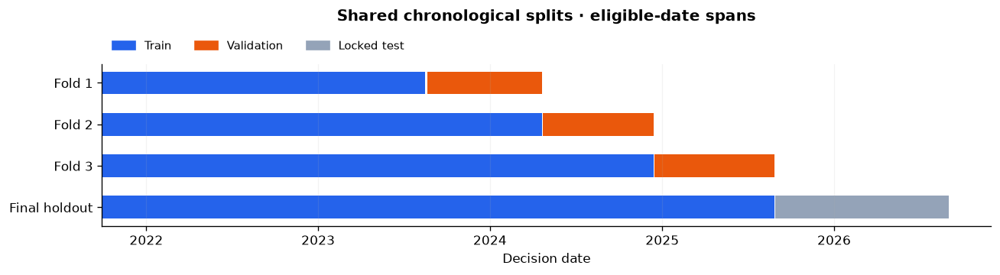

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.1))
for row, fold_id in enumerate(sorted(folds.fold.unique())):
    for role, color in [("train", COLORS[0]), ("validation", COLORS[1])]:
        dates = folds.loc[folds.fold.eq(fold_id) & folds.role.eq(role), "Date"]
        left = mdates.date2num(dates.min())
        width = mdates.date2num(dates.max()) - left + 1
        ax.barh(row, width, left=left, height=.55, color=color)
for role, color in [("train", COLORS[0]), ("test", "#94a3b8")]:
    dates = final.loc[final.role.eq(role), "Date"]
    ax.barh(3, mdates.date2num(dates.max()) - mdates.date2num(dates.min()) + 1,
            left=mdates.date2num(dates.min()), height=.55, color=color)
ax.set_yticks(range(4), ["Fold 1", "Fold 2", "Fold 3", "Final holdout"])
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Shared chronological splits · eligible-date spans", pad=34)
ax.set_xlabel("Decision date")
ax.legend(handles=[Patch(color=COLORS[0], label="Train"), Patch(color=COLORS[1], label="Validation"),
                   Patch(color="#94a3b8", label="Locked test")], loc="lower left", bbox_to_anchor=(0, 1.01),
          ncol=3, frameon=False, fontsize=9)
ax.grid(axis="x", alpha=.15)
fig.tight_layout()
plt.show()


## Token diagnostics

Lengths count special tokens before truncation. Coverage counts each retained article once within its fold/role; articles may recur in later expanding training folds.


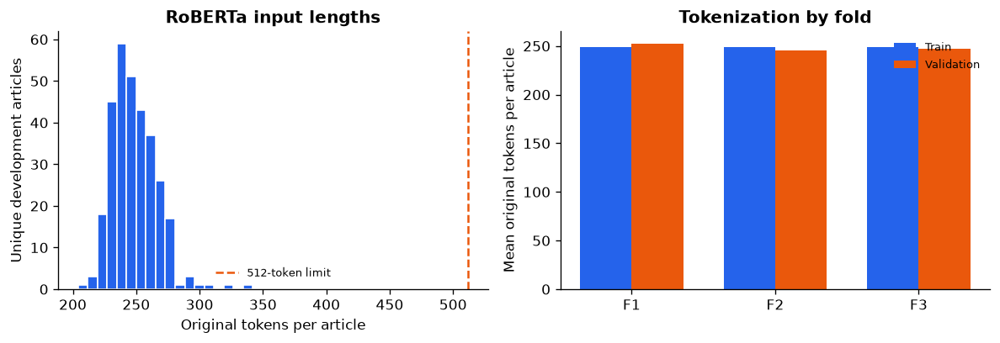

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(token_lengths, bins=18, color=COLORS[0], edgecolor="white")
axes[0].axvline(MAX_TOKENS, color=COLORS[1], linestyle="--", label="512-token limit")
axes[0].set(xlabel="Original tokens per article", ylabel="Unique development articles", title="RoBERTa input lengths")
axes[0].legend(frameon=False, fontsize=8)
x = np.arange(len(folds.fold.unique()))
for offset, role, color in [(-.18, "train", COLORS[0]), (.18, "validation", COLORS[1])]:
    sample = text_coverage_summary.loc[text_coverage_summary.role.eq(role)]
    axes[1].bar(x + offset, sample.mean_original_tokens, width=.36, label=role.title(), color=color)
axes[1].set_xticks(x, [f"F{i}" for i in sorted(folds.fold.unique())])
axes[1].set(ylabel="Mean original tokens per article", title="Tokenization by fold")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


## Training and metrics

Same MLP `(64, 32)`, seeds `[42, 123, 2026]`, Adam settings, 200-epoch cap, patience 25, threshold 0.5, and checkpoint rule `(MCC, macro-F1, -log loss)` as R1–R3. No encoder fine-tuning or additional hyperparameter search.

Primary: MCC. Also report macro-F1, balanced accuracy, accuracy, per-class precision/recall/F1, ROC-AUC, Brier, log loss, and 10-bin ECE. Average individual seed scores within each fold, then weight folds equally. No prediction ensembling.


In [6]:
def score_binary(y, probability):
    y = np.asarray(y, dtype=int)
    probability = np.asarray(probability, dtype=float)
    assert len(y) == len(probability) and len(y)
    assert np.isin(y, [0, 1]).all() and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    pred = (probability >= .5).astype(int)
    tn, fp, fn, tp = [int(np.sum((y == actual) & (pred == predicted)))
                      for actual, predicted in [(0, 0), (0, 1), (1, 0), (1, 1)]]
    divide = lambda a, b: a / b if b else 0.
    precision_down, recall_down = divide(tn, tn + fn), divide(tn, tn + fp)
    precision_up, recall_up = divide(tp, tp + fp), divide(tp, tp + fn)
    f1_down = divide(2 * precision_down * recall_down, precision_down + recall_down)
    f1_up = divide(2 * precision_up * recall_up, precision_up + recall_up)
    both = bool(np.unique(y).size == 2)
    denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    mcc = divide(tp * tn - fp * fn, denominator) if both else np.nan
    n_up, n_down = int(y.sum()), int(len(y) - y.sum())
    ranks = pd.Series(probability).rank(method="average").to_numpy()
    auc = ((ranks[y == 1].sum() - n_up * (n_up + 1) / 2) / (n_up * n_down)) if both else np.nan
    clipped = np.clip(probability, 1e-15, 1 - 1e-15)
    bins = np.minimum((probability * 10).astype(int), 9)
    ece = sum(np.mean(bins == b) * abs(probability[bins == b].mean() - y[bins == b].mean())
              for b in np.unique(bins))
    return {"n": len(y), "n_down": n_down, "n_up": n_up,
            "mcc": mcc, "macro_f1": (f1_down + f1_up) / 2,
            "balanced_accuracy": (recall_down + recall_up) / 2 if both else np.nan,
            "accuracy": float((pred == y).mean()), "roc_auc": float(auc),
            "brier": float(np.mean((probability - y) ** 2)),
            "log_loss": float(-np.mean(y * np.log(clipped) + (1 - y) * np.log1p(-clipped))),
            "ece_10": float(ece), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision_down": precision_down, "recall_down": recall_down, "f1_down": f1_down,
            "precision_up": precision_up, "recall_up": recall_up, "f1_up": f1_up}

perfect = score_binary([0, 0, 1, 1], [0., 0., 1., 1.])
constant = score_binary([0, 0, 1, 1], [.6] * 4)
assert perfect["mcc"] == perfect["macro_f1"] == perfect["roc_auc"] == 1
assert constant["mcc"] == 0 and constant["balanced_accuracy"] == constant["roc_auc"] == .5
assert np.isclose(constant["macro_f1"], 1 / 3) and np.isclose(constant["brier"], .26)
assert score_binary([0, 0, 1, 1], [1., 1., 0., 0.])["mcc"] == -1
assert np.isnan(score_binary([1, 1], [.6, .6])["roc_auc"])
print("Metric checks passed.")


Metric checks passed.


## Concat and train-only scaling

Input order: `[market, 768-D RoBERTa, log1p(n_berita), has_news]`. Market scaling is centered; text scaling uses news-present training rows without centering; availability uses all training rows without centering. Empty windows stay zero. Shared initialization matches R1–R3.


In [7]:
class BlockScaler:
    def fit(self, frame):
        self.market = StandardScaler().fit(frame[MARKET_FEATURES])
        news = frame.loc[frame.has_news.eq(1), TEXT_FEATURES]
        if len(news) == 0:
            raise ValueError("This training split has no news; review the corpus/split before fitting a text baseline.")
        self.text = StandardScaler(with_mean=False).fit(news)
        self.availability = StandardScaler(with_mean=False).fit(frame[AVAIL_FEATURES])
        self.mean_ = np.r_[self.market.mean_, np.zeros(len(TEXT_FEATURES) + len(AVAIL_FEATURES))]
        self.scale_ = np.r_[self.market.scale_, self.text.scale_, self.availability.scale_]
        self.n_samples_seen_, self.news_n_samples_seen_ = len(frame), len(news)
        return self

    def transform(self, frame):
        result = (frame[FEATURES].to_numpy(dtype=float) - self.mean_) / self.scale_
        empty = frame.has_news.eq(0).to_numpy()
        assert not result[empty, len(MARKET_FEATURES):].any()
        assert np.isfinite(result).all()
        return result

class MarketAlignedMLP(MLPClassifier):
    def _init_coef(self, fan_in, fan_out, dtype):
        if fan_in != len(FEATURES):
            return super()._init_coef(fan_in, fan_out, dtype)
        market_weights, bias = super()._init_coef(len(MARKET_FEATURES), fan_out, dtype)
        blocks = [market_weights]
        for width, offset in [(len(TEXT_FEATURES), 1000003), (len(AVAIL_FEATURES), 2000003)]:
            rng = check_random_state(int(self.random_state) + offset)
            bound = np.sqrt(6. / (width + fan_out))
            blocks.append(rng.uniform(-bound, bound, (width, fan_out)).astype(dtype))
        return np.vstack(blocks), bias

for seed in SEEDS:
    reference = MLPClassifier(**MLP_CONFIG, random_state=seed)
    extended = MarketAlignedMLP(**MLP_CONFIG, random_state=seed)
    reference._random_state, extended._random_state = check_random_state(seed), check_random_state(seed)
    for old_in, new_in, width in [(len(MARKET_FEATURES), len(FEATURES), 64), (64, 64, 32), (32, 32, 1)]:
        old_weights, old_bias = reference._init_coef(old_in, width, np.float64)
        new_weights, new_bias = extended._init_coef(new_in, width, np.float64)
        assert np.array_equal(old_weights, new_weights[:old_in]) and np.array_equal(old_bias, new_bias)

print("Common classifier initial arrays verified; train-only scaler checks run inside each fit.")


Common classifier initial arrays verified; train-only scaler checks run inside each fit.


In [8]:
predictions_list, result_rows, fit_rows, history_rows, snapshots = [], [], [], [], []

def make_model(seed):
    return MarketAlignedMLP(**MLP_CONFIG, random_state=int(seed))

def train_model(train, validation, seed, run, fixed_epochs=None):
    start = time.perf_counter()
    scaler = BlockScaler().fit(train)
    assert scaler.n_samples_seen_ == len(train)
    assert np.allclose(scaler.market.mean_, train[MARKET_FEATURES].mean().to_numpy())
    assert scaler.news_n_samples_seen_ == train.has_news.sum()
    x_train, y_train = scaler.transform(train), train.y.to_numpy(dtype=int)
    x_val = scaler.transform(validation) if validation is not None else None
    model, best_model, best_key, best_epoch, stale = make_model(seed), None, None, 0, 0
    limit = int(fixed_epochs) if fixed_epochs is not None else MAX_EPOCHS
    with threadpool_limits(limits=1):
        for epoch in range(1, limit + 1):
            model.partial_fit(x_train, y_train, classes=np.array([0, 1]))
            if validation is None:
                continue
            val_probability = model.predict_proba(x_val)[:, 1]
            score = score_binary(validation.y, val_probability)
            train_loss = score_binary(y_train, model.predict_proba(x_train)[:, 1])["log_loss"]
            history_rows.append({"run": run, "seed": seed, "epoch": epoch,
                                 "train_log_loss": train_loss, "val_log_loss": score["log_loss"],
                                 "val_mcc": score["mcc"], "val_macro_f1": score["macro_f1"]})
            key = (score["mcc"], score["macro_f1"], -score["log_loss"])
            if best_key is None or key > best_key:
                best_model, best_key, best_epoch, stale = copy.deepcopy(model), key, epoch, 0
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    if validation is None:
        best_model, best_epoch = model, limit
    return scaler, best_model, best_epoch, epoch, (time.perf_counter() - start) * 1000

def evaluate_run(run, train, evaluation, role, fixed_epoch_by_seed=None):
    for seed in SEEDS:
        fixed_epochs = None if fixed_epoch_by_seed is None else fixed_epoch_by_seed[seed]
        scaler, model, best_epoch, epochs_run, fit_ms = train_model(
            train, evaluation if fixed_epochs is None else None, seed, run, fixed_epochs)
        start = time.perf_counter()
        with threadpool_limits(limits=1):
            probability = model.predict_proba(scaler.transform(evaluation))[:, 1]
        predict_ms = (time.perf_counter() - start) * 1000
        parameter_count = sum(a.size for a in [*model.coefs_, *model.intercepts_])
        scored = score_binary(evaluation.y, probability)
        result_rows.append({"run": run, "role": role, "seed": seed, **scored})
        fit_rows.append({"run": run, "seed": seed, "train_n": len(train), "feature_count": len(FEATURES),
                         "train_up": int(train.y.eq(1).sum()), "train_news_days": scaler.news_n_samples_seen_, "best_epoch": best_epoch, "epochs_run": epochs_run,
                         "fit_ms": fit_ms, "predict_ms": predict_ms, "trainable_parameters": parameter_count, "frozen_encoder_parameters": encoder_info["frozen_parameters"]})
        columns = ["Date", "target_date", "y", "n_berita", "has_news", "target_weekday", "realized_target_gap_days"]
        output = evaluation[columns].copy()
        output["run"], output["role"], output["model_id"], output["training_seed"] = run, role, MODEL_ID, seed
        output["p_up"], output["y_pred"] = probability, (probability >= .5).astype(int)
        predictions_list.append(output)
        # Keep the selected weights/scaler in the notebook's result bundle.
        snapshot = {"run": run, "seed": seed, "features": FEATURES, "best_epoch": best_epoch,
                    "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
                    "scaler_training_rows": scaler.n_samples_seen_, "text_scaler_training_rows": scaler.news_n_samples_seen_,
                    "coefs": [a.tolist() for a in model.coefs_], "intercepts": [a.tolist() for a in model.intercepts_],
                    "classes": model.classes_.tolist(), "activation": "relu", "output_activation": "logistic"}
        z = (evaluation[FEATURES].to_numpy(dtype=float) - scaler.mean_) / scaler.scale_
        for weights, bias in zip(model.coefs_[:-1], model.intercepts_[:-1]):
            z = np.maximum(0., z @ weights + bias)
        logits = (z @ model.coefs_[-1] + model.intercepts_[-1]).ravel()
        assert np.allclose(1 / (1 + np.exp(-np.clip(logits, -700, 700))), probability)
        snapshots.append(snapshot)
        print(f"{run} seed={seed}: best epoch {best_epoch}, MCC={scored['mcc']:.4f}")

for fold_id in sorted(folds.fold.unique()):
    train = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("train")])
    val = take_rows(folds.loc[folds.fold.eq(fold_id) & folds.role.eq("validation")])
    evaluate_run(f"fold_{fold_id}", train, val, "validation")

if RUN_FINAL_TEST:
    fixed_epoch_by_seed = {seed: int(np.median([r["best_epoch"] for r in fit_rows if r["seed"] == seed])) for seed in SEEDS}
    evaluate_run("final_test", final_train, take_rows(final.loc[final.role.eq("test")]), "test", fixed_epoch_by_seed)

predictions = pd.concat(predictions_list, ignore_index=True)
seed_results, fits, history = pd.DataFrame(result_rows), pd.DataFrame(fit_rows), pd.DataFrame(history_rows)
assert not predictions.duplicated(["role", "training_seed", "Date"]).any()
for seed in SEEDS:
    assert len(predictions.loc[predictions.role.eq("validation") & predictions.training_seed.eq(seed)]) == len(seen_validation_dates)
numeric = [c for c in seed_results.select_dtypes(include="number") if c != "seed"]
results = seed_results.groupby(["run", "role"], sort=False)[numeric].mean().reset_index()
for field in ["n", "n_down", "n_up"]:
    results[field] = results[field].astype(int)
seed_std = seed_results.groupby("run", sort=False)[METRICS].std(ddof=1)
validation_results = results.loc[results.role.eq("validation"), METRICS]
display(fits.round(3))
display(seed_results[["run", "seed", "n", *METRICS]].round(4))
display(results[["run", "role", "n", *METRICS]].round(4))
display(seed_std.rename_axis("run").round(4))
display(pd.DataFrame({"mean_validation": validation_results.mean(),
                      "std_across_folds": validation_results.std(ddof=1)}).round(4))
print("n counts unique dates; fold metrics average individual-seed scores, without ensembling.")
print("Final test scored." if RUN_FINAL_TEST else "Final-test scoring remains locked.")
assert array_sha256(vectors) == encoder_info["article_vectors_sha256"]
assert fits.trainable_parameters.eq(52353).all()
assert fits.feature_count.eq(784).all()


fold_1 seed=42: best epoch 9, MCC=0.0094


fold_1 seed=123: best epoch 2, MCC=0.0566


fold_1 seed=2026: best epoch 11, MCC=0.1252


fold_2 seed=42: best epoch 12, MCC=0.1078


fold_2 seed=123: best epoch 32, MCC=0.1230


fold_2 seed=2026: best epoch 3, MCC=0.1803


... (5 outputs left out)

,run,role,n,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
0,fold_1,validation,158,0.0637,0.5231,0.5306,0.5612,0.5273,0.2597,0.7551,0.0966
1,fold_2,validation,159,0.1370,0.5214,0.5567,0.5618,0.5306,0.2925,0.9122,0.1712
2,fold_3,validation,158,0.0618,0.5003,0.5274,0.5274,0.5509,0.2792,0.8453,0.1501


,mcc,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,log_loss,ece_10
run,,,,,,,,
fold_1,0.0582,0.0330,0.0301,0.0203,0.0235,0.0074,0.0477,0.0211
fold_2,0.0382,0.0267,0.0160,0.0158,0.0162,0.0085,0.1136,0.0246
fold_3,0.0153,0.0124,0.0073,0.0073,0.0286,0.0438,0.2440,0.1138


,mean_validation,std_across_folds
mcc,0.0875,0.0429
macro_f1,0.5150,0.0127
balanced_accuracy,0.5382,0.0160
accuracy,0.5502,0.0197
roc_auc,0.5363,0.0128
brier,0.2771,0.0165
log_loss,0.8376,0.0788
ece_10,0.1393,0.0385


n counts unique dates; fold metrics average individual-seed scores, without ensembling.
Final-test scoring remains locked.


## Sampling uncertainty

95% conditional intervals: 1,000 circular moving-block resamples of 10 evaluated observations. Sample the same dates across seeds. Intervals describe fixed predictions, without retraining uncertainty.


In [9]:
def block_intervals(frame, seed):
    reference = frame.loc[frame.training_seed.eq(SEEDS[0])].sort_values("Date")
    y = reference.y.to_numpy(dtype=int)
    probabilities = []
    for training_seed in SEEDS:
        rows = frame.loc[frame.training_seed.eq(training_seed)].sort_values("Date")
        assert rows.Date.tolist() == reference.Date.tolist() and rows.y.tolist() == reference.y.tolist()
        probabilities.append(rows.p_up.to_numpy(dtype=float))
    n, rng = len(y), np.random.default_rng(seed)
    length = min(BLOCK_LENGTH, n)
    sampled = {metric: [] for metric in METRICS}
    for _ in range(BOOTSTRAP_REPEATS):
        starts = rng.integers(0, n, size=int(np.ceil(n / length)))
        positions = ((starts[:, None] + np.arange(length)) % n).ravel()[:n]
        scores = [score_binary(y[positions], p[positions]) for p in probabilities]
        for metric in METRICS:
            values = [r[metric] for r in scores]
            sampled[metric].append(float(np.mean(values)))
    output = []
    for metric, values in sampled.items():
        valid = np.asarray(values, dtype=float)
        valid = valid[np.isfinite(valid)]
        low, high = np.quantile(valid, [.025, .975]) if len(valid) else [np.nan, np.nan]
        output.append({"metric": metric, "low_95": float(low), "high_95": float(high), "valid_resamples": len(valid)})
    return output

interval_rows = []
for run_index, run in enumerate(results.run, 1):
    for interval in block_intervals(predictions.loc[predictions.run.eq(run)], BOOTSTRAP_SEED + run_index):
        interval_rows.append({"run": run, **interval})
intervals = pd.DataFrame(interval_rows)
display(intervals.loc[intervals.metric.isin(["mcc", "macro_f1", "balanced_accuracy", "accuracy"])].round(4))


,run,metric,low_95,high_95,valid_resamples
0,fold_1,mcc,-0.0178,0.1579,1000
1,fold_1,macro_f1,0.4786,0.5683,1000
2,fold_1,balanced_accuracy,0.4916,0.5753,1000
3,fold_1,accuracy,0.5232,0.6055,1000
8,fold_2,mcc,0.0289,0.2424,1000
9,fold_2,macro_f1,0.4470,0.5886,1000
10,fold_2,balanced_accuracy,0.5115,0.6043,1000
11,fold_2,accuracy,0.4864,0.6290,1000
16,fold_3,mcc,-0.0716,0.2066,1000
17,fold_3,macro_f1,0.4312,0.5675,1000


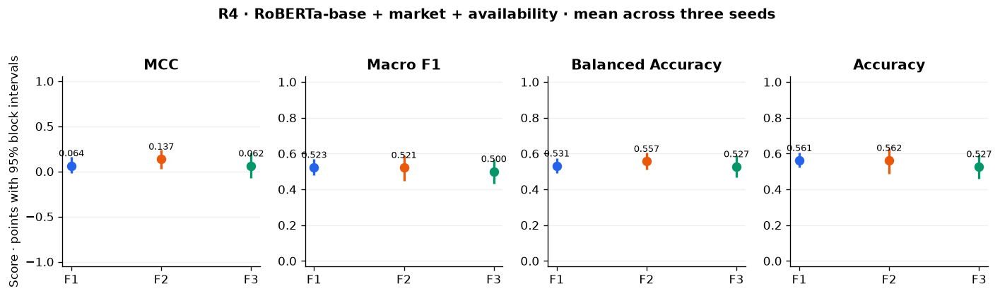

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, metric in zip(axes, ["mcc", "macro_f1", "balanced_accuracy", "accuracy"]):
    for index, row in results.reset_index(drop=True).iterrows():
        bounds = intervals.loc[intervals.run.eq(row["run"]) & intervals.metric.eq(metric)].iloc[0]
        value = row[metric]
        ax.vlines(index, bounds.low_95, bounds.high_95, color=COLORS[index % 3], linewidth=2)
        ax.scatter(index, value, color=COLORS[index % 3], s=50, zorder=3)
        ax.annotate(f"{value:.3f}", (index, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(results)), results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set_title(metric.replace("_", " ").upper() if metric == "mcc" else metric.replace("_", " ").title())
    ax.set_ylim(-1.05, 1.05) if metric == "mcc" else ax.set_ylim(-.03, 1.03)
    ax.grid(axis="y", alpha=.2)
axes[0].set_ylabel("Score · points with 95% block intervals")
fig.suptitle("R4 · RoBERTa-base + market + availability · mean across three seeds", y=1.04, fontweight="bold")
fig.tight_layout()
plt.show()


## Training curves

Solid = validation log loss; dashed = training log loss. Mark the checkpoint selected by MCC, macro-F1, then log loss.


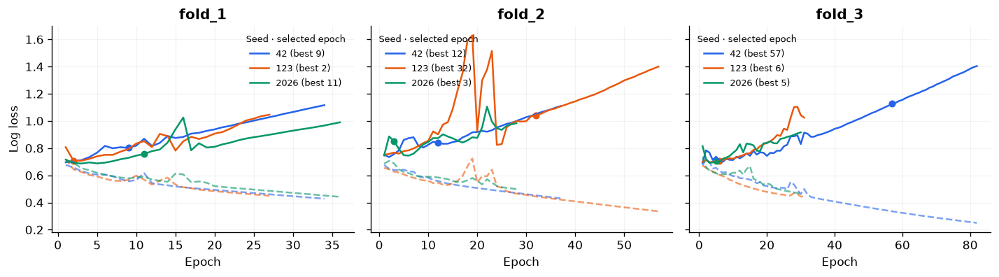

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, run in zip(axes, [f"fold_{i}" for i in sorted(folds.fold.unique())]):
    for index, seed in enumerate(SEEDS):
        curve = history.loc[history.run.eq(run) & history.seed.eq(seed)]
        best_epoch = int(fits.loc[fits.run.eq(run) & fits.seed.eq(seed), "best_epoch"].iloc[0])
        ax.plot(curve.epoch, curve.val_log_loss, color=COLORS[index], label=f"{seed} (best {best_epoch})")
        ax.plot(curve.epoch, curve.train_log_loss, "--", color=COLORS[index], alpha=.6)
        selected = curve.loc[curve.epoch.eq(best_epoch)].iloc[0]
        ax.scatter([best_epoch], [selected.val_log_loss], s=25, color=COLORS[index])
    ax.set(title=run, xlabel="Epoch")
    ax.grid(alpha=.15)
    ax.legend(title="Seed · selected epoch", fontsize=8, title_fontsize=8, frameon=False)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
plt.show()


## Classes and probability quality

Confusion annotations average counts across three seeds. Calibration pools seed entries and reports unique-date counts; entries are not independent observations.


,run,class,support,precision,recall,f1
0,fold_1,DOWN,64,0.4470,0.3698,0.3961
1,fold_1,UP,94,0.6197,0.6915,0.6501
2,fold_2,DOWN,78,0.6203,0.2821,0.3842
3,fold_2,UP,81,0.5462,0.8313,0.6586
4,fold_3,DOWN,79,0.5507,0.2954,0.3842
5,fold_3,UP,79,0.5188,0.7595,0.6164


,run,bin,prediction_entries,unique_dates,predicted_up,observed_up
0,fold_1,0,10,7,0.0437,0.6000
1,fold_1,1,6,6,0.1577,0.5000
2,fold_1,2,7,7,0.2519,0.5714
3,fold_1,3,6,6,0.3748,0.5000
4,fold_1,4,129,82,0.4649,0.5504
5,fold_1,5,181,110,0.5481,0.6022
6,fold_1,6,79,55,0.6374,0.6203
7,fold_1,7,28,20,0.7379,0.7500
8,fold_1,8,13,10,0.8375,0.5385
9,fold_1,9,15,8,0.9729,0.6000


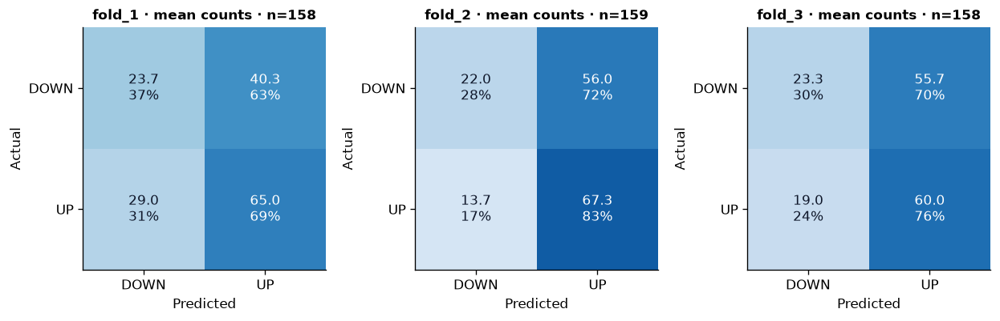

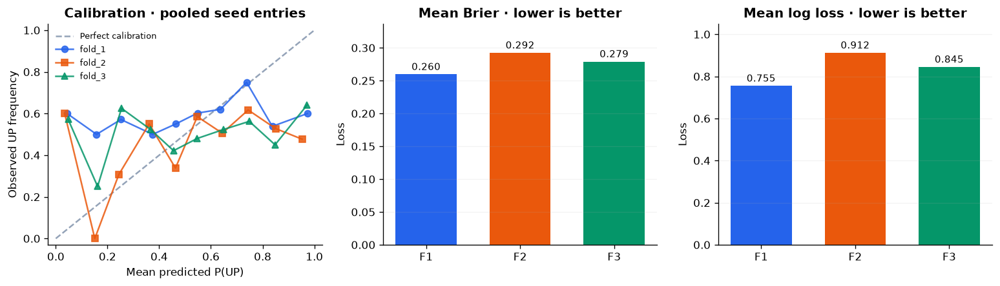

In [12]:
class_rows, calibration_rows = [], []
for row in results.to_dict("records"):
    for label, suffix in [("DOWN", "down"), ("UP", "up")]:
        class_rows.append({"run": row["run"], "class": label, "support": row[f"n_{suffix}"],
                           "precision": row[f"precision_{suffix}"], "recall": row[f"recall_{suffix}"], "f1": row[f"f1_{suffix}"]})
for run, frame in predictions.groupby("run", sort=False):
    bin_ids = np.minimum((frame.p_up.to_numpy() * 10).astype(int), 9)
    for bin_id in np.unique(bin_ids):
        group = frame.loc[bin_ids == bin_id]
        calibration_rows.append({"run": run, "bin": int(bin_id), "prediction_entries": len(group),
                                 "unique_dates": group.Date.nunique(), "predicted_up": float(group.p_up.mean()),
                                 "observed_up": float(group.y.mean())})
per_class, calibration = pd.DataFrame(class_rows), pd.DataFrame(calibration_rows)
display(per_class.round(4))
display(calibration.round(4))

fig, axes = plt.subplots(1, len(results), figsize=(3.5 * len(results), 3.3), squeeze=False)
for ax, row in zip(axes.ravel(), results.to_dict("records")):
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    totals = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, totals, out=np.zeros_like(matrix, dtype=float), where=totals != 0)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for actual in range(2):
        for predicted in range(2):
            ax.text(predicted, actual, f"{matrix[actual, predicted]:.1f}\n{normalized[actual, predicted]:.0%}",
                    ha="center", va="center", color="white" if normalized[actual, predicted] > .6 else "#0f172a")
    ax.set_xticks([0, 1], LABELS)
    ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{row['run']} · mean counts · n={row['n']}", fontsize=10)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot([0, 1], [0, 1], "--", color="#94a3b8", label="Perfect calibration")
for index, (run, frame) in enumerate(calibration.groupby("run", sort=False)):
    frame = frame.sort_values("predicted_up")
    axes[0].plot(frame.predicted_up, frame.observed_up, marker=["o", "s", "^"][index % 3],
                 color=COLORS[index % 3], alpha=.85, label=run)
axes[0].set(xlim=(-.03, 1.03), ylim=(-.03, 1.03), xlabel="Mean predicted P(UP)",
            ylabel="Observed UP frequency", title="Calibration · pooled seed entries")
axes[0].legend(fontsize=8, frameon=False)
x = np.arange(len(results))
for ax, metric, title in [(axes[1], "brier", "Mean Brier · lower is better"),
                           (axes[2], "log_loss", "Mean log loss · lower is better")]:
    ax.bar(x, results[metric], color=[COLORS[i % 3] for i in x], width=.65)
    ax.set_xticks(x, results.run.str.replace("fold_", "F").str.replace("final_test", "Test"))
    ax.set(title=title, ylabel="Loss", ylim=(0, max(float(results[metric].max()) * 1.15, .01)))
    for i, value in enumerate(results[metric]):
        ax.annotate(f"{value:.3f}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.grid(axis="y", alpha=.15)
fig.tight_layout()
plt.show()


## Coverage and subgroups

Retain empty, singleton, and multi-article dates. Weekday/gap groups use the target endpoint and remain diagnostic.


,run,group,n,mcc,macro_f1,balanced_accuracy,accuracy
0,fold_1,all,158,0.0637,0.5231,0.5306,0.5612
1,fold_1,news_present,21,-0.0093,0.4889,0.4954,0.5079
2,fold_1,empty,137,0.0744,0.5274,0.5355,0.5693
3,fold_1,singleton,13,-0.1133,0.4373,0.4458,0.4872
4,fold_1,multi_article,8,0.0861,0.5286,0.5417,0.5417
5,fold_1,target_Monday,30,-0.0661,0.4234,0.4759,0.5222
6,fold_1,target_other_weekday,128,0.0972,0.5390,0.5469,0.5703
7,fold_1,target_gap_1d,122,0.0944,0.5363,0.5453,0.5683
8,fold_1,target_gap_3d,28,-0.0291,0.4355,0.4861,0.5357
9,fold_1,target_gap_other,8,0.1260,0.4990,0.5417,0.5417


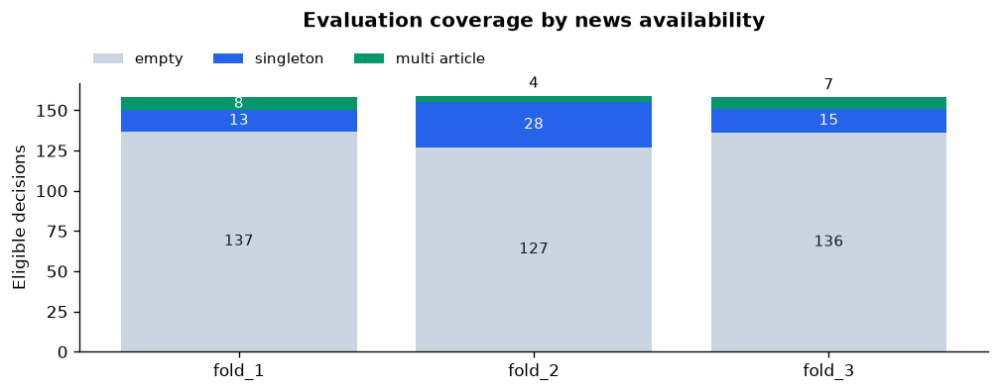

In [13]:
subgroup_rows = []
for run, all_seeds in predictions.groupby("run", sort=False):
    frame = all_seeds.loc[all_seeds.training_seed.eq(SEEDS[0])].sort_values("Date")
    masks = {"all": np.ones(len(frame), dtype=bool), "news_present": frame.n_berita.gt(0),
             "empty": frame.n_berita.eq(0), "singleton": frame.n_berita.eq(1),
             "multi_article": frame.n_berita.gt(1), "target_Monday": frame.target_weekday.eq(0),
             "target_other_weekday": frame.target_weekday.ne(0), "target_gap_1d": frame.realized_target_gap_days.eq(1),
             "target_gap_3d": frame.realized_target_gap_days.eq(3),
             "target_gap_other": ~frame.realized_target_gap_days.isin([1, 3])}
    for name, mask in masks.items():
        dates = frame.loc[mask, "Date"]
        selected = all_seeds.loc[all_seeds.Date.isin(dates)]
        if len(dates):
            scores = pd.DataFrame([score_binary(g.y, g.p_up) for _, g in selected.groupby("training_seed")]).mean().to_dict()
        else:
            scores = {m: np.nan for m in METRICS}
        subgroup_rows.append({"run": run, "group": name, **scores, "n": len(dates)})
subgroups = pd.DataFrame(subgroup_rows)
display(subgroups[["run", "group", "n", "mcc", "macro_f1", "balanced_accuracy", "accuracy"]].round(4))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
coverage = subgroups.loc[subgroups.group.isin(["empty", "singleton", "multi_article"])].pivot(index="run", columns="group", values="n")
coverage = coverage.reindex(results.run)
bottom = np.zeros(len(coverage))
for group, color in [("empty", "#cbd5e1"), ("singleton", COLORS[0]), ("multi_article", COLORS[2])]:
    values = coverage[group].to_numpy()
    ax.bar(coverage.index, values, bottom=bottom, color=color, label=group.replace("_", " "))
    for index, (base, value) in enumerate(zip(bottom, values)):
        if value >= 8:
            ax.text(index, base + value / 2, str(int(value)), ha="center", va="center", fontsize=9,
                    color="#0f172a" if group == "empty" else "white")
        elif value:
            ax.annotate(str(int(value)), (index, base + value), xytext=(0, 5),
                        textcoords="offset points", ha="center", fontsize=9)
    bottom += values
ax.set_ylabel("Eligible decisions")
ax.set_title("Evaluation coverage by news availability", pad=34)
ax.legend(frameon=False, ncol=3, bbox_to_anchor=(0, 1.01), loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()


## Development comparison

Compare the four declared candidates using their saved validation results. Select the best overall and the best Level 3-eligible representation by mean fold MCC, then macro-F1. R3 reuses L1-d and is not an independent repeated fit. The text-only follow-up remains a separate condition.


In [14]:
candidate_rows, comparison_sources = [], {}
shared_keys = ["training_seeds", "model", "max_epochs", "patience", "selection", "scaler_fit", "bootstrap", "score_aggregation"]
for candidate_id, filename, eligible in [("R1", "01_tfidf_svd.ipynb", False),
                                         ("R2", "02_pretrained_word2vec.ipynb", True),
                                         ("R3", "03_finbert.ipynb", True)]:
    path = ROOT / "deira-work/ablation_study/level_2" / filename
    saved = json.loads(path.read_text())
    bundle = [o["data"]["application/json"] for c in saved["cells"] for o in c.get("outputs", [])
              if "application/json" in o.get("data", {})][-1]
    metadata = bundle["metadata"]
    assert metadata["model_id"] == candidate_id and not metadata["final_test_evaluated"]
    assert metadata["source_sha256"] == pipeline["input_sha256"]
    for relative, expected in metadata["artifact_sha256"].items():
        assert sha256(ROOT / relative) == expected
    for key in ["training_seeds", "model", "max_epochs", "patience"]:
        expected = {"training_seeds": SEEDS, "model": json.loads(json.dumps(MLP_CONFIG)),
                    "max_epochs": MAX_EPOCHS, "patience": PATIENCE}[key]
        assert metadata[key] == expected
    if comparison_sources:
        reference = next(iter(comparison_sources.values()))["metadata"]
        for key in shared_keys:
            assert metadata[key] == reference[key], key
    reference_predictions = pd.DataFrame(bundle["predictions"])
    for date_col in ["Date", "target_date"]:
        reference_predictions[date_col] = pd.to_datetime(reference_predictions[date_col])
    keys = ["run", "training_seed", "Date"]
    current = predictions.sort_values(keys).reset_index(drop=True)
    previous = reference_predictions.sort_values(keys).reset_index(drop=True)
    for field in [*keys, "target_date", "y", "n_berita", "has_news"]:
        assert current[field].tolist() == previous[field].tolist(), (candidate_id, field)
    scores = pd.DataFrame(bundle["metrics"]).loc[lambda x: x.role.eq("validation")]
    comparison_sources[candidate_id] = {"metadata": metadata, "notebook": str(path.relative_to(ROOT)), "sha256": sha256(path)}
    candidate_rows.append({"model_id": candidate_id, "level_3_eligible": eligible,
                           **{f"mean_{key}": float(scores[key].mean()) for key in METRICS},
                           "fold_std_mcc": float(scores.mcc.std(ddof=1))})
candidate_rows.append({"model_id": MODEL_ID, "level_3_eligible": True,
                       **{f"mean_{key}": float(validation_results[key].mean()) for key in METRICS},
                       "fold_std_mcc": float(validation_results.mcc.std(ddof=1))})
representation_comparison = pd.DataFrame(candidate_rows)
ranked = representation_comparison.sort_values(["mean_mcc", "mean_macro_f1", "model_id"], ascending=[False, False, True])
best_overall = ranked.iloc[0].model_id
best_eligible = ranked.loc[ranked.level_3_eligible].iloc[0].model_id
display(representation_comparison.round(4))
print(f"Best overall: {best_overall} | Best Level 3-eligible: {best_eligible}")
print("Validation selection only; no final-test results. Text-only follow-up is not run here.")


,model_id,level_3_eligible,mean_mcc,mean_macro_f1,mean_balanced_accuracy,mean_accuracy,mean_roc_auc,mean_brier,mean_log_loss,mean_ece_10,fold_std_mcc
0,R1,False,0.0926,0.5189,0.5404,0.5551,0.5439,0.2599,0.7306,0.0991,0.0598
1,R2,True,0.1130,0.5376,0.5521,0.5599,0.5562,0.2737,0.8565,0.1455,0.0834
2,R3,True,0.1255,0.5418,0.5572,0.5662,0.5579,0.2698,0.9047,0.1372,0.0730
3,R4,True,0.0875,0.5150,0.5382,0.5502,0.5363,0.2771,0.8376,0.1393,0.0429


Best overall: R3 | Best Level 3-eligible: R3
Validation selection only; no final-test results. Text-only follow-up is not run here.


## Result bundle

Embed metrics, intervals, predictions, selected classifier weights/scalers, encoder hashes, token coverage, and validation selection. Temporary model/embedding caches live outside the repository. This is a fresh R4 run; the final test remains locked.


In [15]:
files = [BASE / name for name in ["fold_manifest.csv", "final_fit_manifest.csv", "calendar_partitions.csv",
                                  "daily_market.csv", "pipeline_manifest.json", "feature_contract.json", "aligned_articles.jsonl", "news_windows.jsonl"]]
run_metadata = {
    "model_id": MODEL_ID, "condition": "roberta_base", "level": 2, "level_3_eligible": True, "run_at_wib": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "final_test_evaluated": RUN_FINAL_TEST, "hard_prediction_rule": "P(UP) >= 0.5; threshold fixed",
    "probability_rule": "MLP logistic output; no calibration fitted",
    "input_predictors": FEATURES, "excluded_predictors": ["future outcomes", "sentiment labels", "legacy aligned dates", "collection tags"],
    "macro_inputs": [], "training_seeds": SEEDS, "threshold_tuned": False,
    "model": MLP_CONFIG, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
    "selection": ["validation MCC", "validation macro-F1", "negative validation log loss"],
    "scaler_fit": "Market: centered train; text: uncentered news-present train; availability: uncentered all train",
    "feature_blocks": {"market": MARKET_FEATURES, "text": TEXT_FEATURES, "availability": AVAIL_FEATURES},
    "shared_initialization": "Market rows and common hidden/output layers match L1-c; extra blocks use independent seeded Glorot",
    "encoder": encoder_report,
    "text_pipeline": {"model": ENCODER_ID, "revision": ENCODER_REVISION, "native_dimension": ENCODER_DIM,
                      "common_text_width": ENCODER_DIM, "token_view": "text_transformer", "frozen": True,
                      "pooling": cache_spec["pooling"], "max_tokens": MAX_TOKENS,
                      "case_preserving": True, "add_prefix_space": False},
    "trainable_encoder_parameters": 0, "input_adapter_parameters": 0,
    "prediction_effective_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "representation_selection": {"criterion": ["mean validation MCC", "mean validation macro-F1"],
                                 "best_overall": best_overall, "best_level_3_eligible": best_eligible,
                                 "text_only_follow_up_completed": False},
    "comparison_sources": {k: {key: value for key, value in v.items() if key != "metadata"}
                           for k, v in comparison_sources.items()},
    "historical_encoder_availability_verified": False,
    "fusion": "concatenation; no query/cross-attention/gate",
    "article_window_aggregation": "uniform mean of token-mean article vectors; empty windows zero",
    "availability_transform": ["log1p(n_berita)", "has_news"], "final_epochs": "Per-seed median best epoch across development folds",
    "trainable_parameters_per_fit": sorted(fits.trainable_parameters.unique().tolist()),
    "score_aggregation": "Mean individual-seed scores within fold, then equal-weight mean across validation folds; no ensemble",
    "bootstrap": {"method": "circular moving blocks", "repeats": BOOTSTRAP_REPEATS,
                  "block_length_evaluated_observations": BLOCK_LENGTH, "base_seed": BOOTSTRAP_SEED,
                  "run_seed_rule": "base_seed + 1-based run index in results", "confidence": .95,
                  "same_sampled_dates_across_training_seeds": True, "conditional_on_fixed_predictions": True},
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                 "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__, "torch": torch.__version__, "transformers": transformers.__version__},
    "artifact_sha256": {str(path.relative_to(ROOT)): sha256(path) for path in files},
    "source_sha256": pipeline["input_sha256"], "alignment_mode": pipeline["config"]["alignment_mode"],
    "geopolitical_policy": pipeline["config"]["geopolitical_policy"],
}
def to_records(frame):
    def clean(value):
        if isinstance(value, (pd.Timestamp, datetime)):
            return value.isoformat()
        if isinstance(value, np.generic):
            return clean(value.item())
        return None if pd.isna(value) else value
    return [{key: clean(value) for key, value in row.items()} for row in frame.to_dict("records")]
result_bundle = {"metadata": run_metadata, "fits": to_records(fits), "metrics": to_records(results),
                 "seed_metrics": to_records(seed_results), "seed_std": to_records(seed_std.reset_index()),
                 "validation_summary": to_records(validation_results.agg(["mean", "std"]).rename_axis("statistic").reset_index()),
                 "intervals": to_records(intervals), "per_class": to_records(per_class), "calibration": to_records(calibration),
                 "subgroups": to_records(subgroups), "predictions": to_records(predictions),
                 "history": to_records(history), "selected_models": snapshots,
                 "token_diagnostics": to_records(token_diagnostics), "text_coverage_summary": to_records(text_coverage_summary),
                 "representation_comparison": to_records(representation_comparison)}
json.dumps(result_bundle, allow_nan=False)
display({"application/json": result_bundle}, raw=True, metadata={"application/json": {"expanded": False}})
print(f"Stored {len(predictions)} seed-specific predictions across {predictions.Date.nunique()} dates; final test evaluated: {RUN_FINAL_TEST}.")


Stored 1425 seed-specific predictions across 475 dates; final test evaluated: False.
